# Valmont : prix de la nuitée (Q3) et fiabilité de la grille (Q4)

**Objectif.** Q3 : proposer, pour une demande qui arrive aujourd'hui, un prix de nuitée cohérent avec la période et l'établissement. Q4 : identifier les périodes où cette grille est fiable et celles où elle se trompe.

**Démarche.** explorer les facteurs qui font varier le prix et formuler des hypothèses, construire un modèle de prédiction et le comparer à un point de référence,  vérifier qu'il généralise sur des réservations non utilisées pour l'apprentissage,  en déduire une grille et mesurer ses erreurs par mois, catégorie et hôtel.

## 1. Charger et vérifier

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, KFold
from sklearn.metrics import mean_squared_error, r2_score

On importe pandas et numpy pour manipuler les données, matplotlib pour les graphiques et scikit-learn pour les modèles (régression linéaire, kNN), la standardisation et les validations. Rien à interpréter à ce stade.

In [11]:
reserv = pd.read_csv('reservations_modelisation_794.csv')
hotel = pd.read_csv('Valmont_hotels.csv')

print('lignes :', len(reserv), ' doublons :', reserv.reservation_id.duplicated().sum(),
      ' valeurs manquantes :', reserv.isna().sum().sum())
print('hôtels inconnus :', set(reserv.hotel_id) - set(hotel.hotel_id))

# la catégorie (3, 4, 5 étoiles) est dans le fichier hôtels : on la rattache à chaque réservation
df = reserv.merge(hotel, on='hotel_id')
df['etoiles'] = df.categorie.str[0].astype(int)
df.shape

lignes : 794  doublons : 0  valeurs manquantes : 0
hôtels inconnus : set()


(794, 21)

On charge les deux fichiers et on contrôle leur qualité : doublons d'identifiant, valeurs manquantes, hôtels présents dans les réservations mais absents du fichier hôtels. On rattache à chaque réservation les caractéristiques de son hôtel (merge) et on extrait le nombre d'étoiles ('4 étoiles' devient '4').

**Résultat.** 794 réservations, 0 doublon, 0 valeur manquante, aucun hôtel inconnu. Le tableau final compte 21 colonnes.

**Conclusion.** Aucune ligne à corriger ni à écarter pour cette partie. Le rattachement est indispensable : la catégorie de l'hôtel, qui s'avère être le facteur dominant du prix, n'existe que dans le fichier hôtels. Remarque : le fichier de réservations fourni contient 794 lignes alors que l'énoncé en annonce 940 ; nous travaillons sur cette version sans la modifier.

## 2. Analyse exploratoire : regarder avant de modéliser

### Les sept nombres

In [12]:
df[['prix_nuit_eur', 'delai_reservation_j', 'nb_nuits']].describe().round(1)

,prix_nuit_eur,delai_reservation_j,nb_nuits
count,794.0,794.0,794.0
mean,195.5,42.2,2.9
std,105.3,40.7,1.5
min,46.6,0.0,1.0
25%,116.1,10.0,2.0
50%,153.0,28.0,3.0
75%,284.9,64.0,4.0
max,481.1,235.0,9.0


**Résultat.** Le prix de la nuitée va de 47 € à 481 €, avec une moyenne de 195,5 € et une médiane de 153 €. Le délai de réservation va de 0 à 235 jours (42 jours en moyenne) et les séjours durent 2,9 nuits en moyenne (de 1 à 9).

**Conclusion.** Les valeurs sont plausibles : aucun prix nul ou négatif, aucune durée aberrante. L'étendue des prix (de 1 à 10) montre qu'il y a des profils très différents dans le fichier, ce que la suite va expliquer.

In [13]:
print('prix : moyenne', round(df.prix_nuit_eur.mean(), 1), ' médiane', round(df.prix_nuit_eur.median(), 1),
      ' écart-type', round(df.prix_nuit_eur.std(), 1))

prix : moyenne 195.5  médiane 153.0  écart-type 105.3


**Résultat.** Moyenne 195,5 €, médiane 153 €, écart-type 105,3 €.

**Conclusion.** La moyenne est nettement au-dessus de la médiane et l'écart-type dépasse la moitié de la moyenne : la distribution est asymétrique, tirée vers le haut par des nuitées chères. Un prix moyen unique ne représenterait donc aucune réservation réelle.

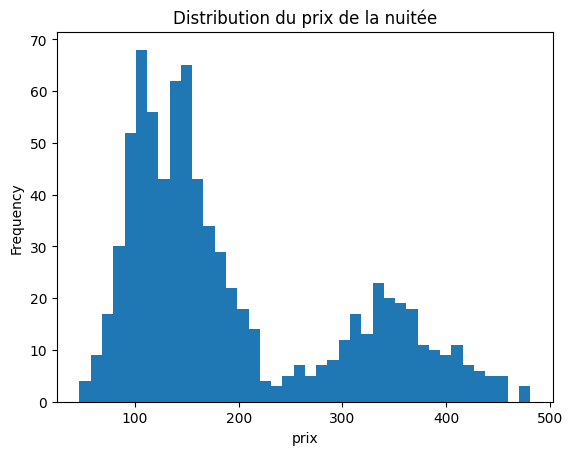

In [14]:
df.prix_nuit_eur.plot(kind='hist', bins=40)
plt.title('Distribution du prix de la nuitée'); plt.xlabel('prix'); plt.show()

**Résultat.** La grande majorité des prix se situe entre 60 et 220 €, puis il y a un creux net entre 220 et 280 € (moins de 10 réservations par classe de 20 €), et un second groupe entre 280 et 460 €.

**Conclusion.** Les prix forment deux ensembles distincts, ce qui suggère que le prix dépend d'une variable qualitative forte. L'hypothèse la plus naturelle est la catégorie de l'hôtel, que l'on teste juste après. Ces prix élevés ne sont pas des valeurs aberrantes à supprimer : ils correspondent à un vrai segment.

### Comparaison du prix selon chaque facteur

In [15]:
df['haute'] = df.mois_sejour.isin([6, 7, 8, 12]).astype(int)    # saison haute, voir graphique plus bas
df['we'] = (df.weekend == 'oui').astype(int)
df['ota'] = (df.canal == 'OTA').astype(int)

for col in ['etoiles', 'haute', 'we', 'canal']:
    print(df.groupby(col).prix_nuit_eur.agg(['count', 'mean', 'median']).round(0), '\n')

         count   mean  median
etoiles                      
3          306  109.0   108.0
4          265  166.0   162.0
5          223  349.0   345.0 

       count   mean  median
haute                      
0        528  181.0   146.0
1        266  225.0   180.0 

    count   mean  median
we                      
0     545  183.0   149.0
1     249  223.0   173.0 

            count   mean  median
canal                           
OTA           337  188.0   150.0
agence         91  198.0   160.0
direct        210  204.0   153.0
entreprise    156  199.0   156.0 



 On crée trois variables à deux valeurs (haute saison, week-end, canal OTA) puis on calcule le prix moyen et médian pour chaque valeur de chaque facteur. La haute saison regroupe les mois 6, 7, 8 et 12, choisis d'après le graphique qui suit.

**Résultat.**
- Catégorie : 109 € (3 étoilestoiles), 166 € (4étoiles), 349 € (5étoiles), soit un facteur 3 entre le plus bas et le plus haut.
- Saison : 181 € en basse saison, 225 € en haute saison (+24 %).
- Semaine / week-end : 183 € contre 223 € (+22 %).
- Canal : 188 € via les plateformes, 198 à 204 € pour les autres canaux (environ 8 % de moins pour les plateformes).

**Conclusion.** Le facteur qui pèse le plus est de loin la catégorie, suivie de la saison et du week-end, puis du canal. Ces écarts sont des moyennes brutes : elles mélangent plusieurs effets (par exemple, si les plateformes vendaient plus de3  étoiles, leur prix moyen serait plus bas pour cette seule raison). Le modèle de régression permettra d'isoler chaque effet.

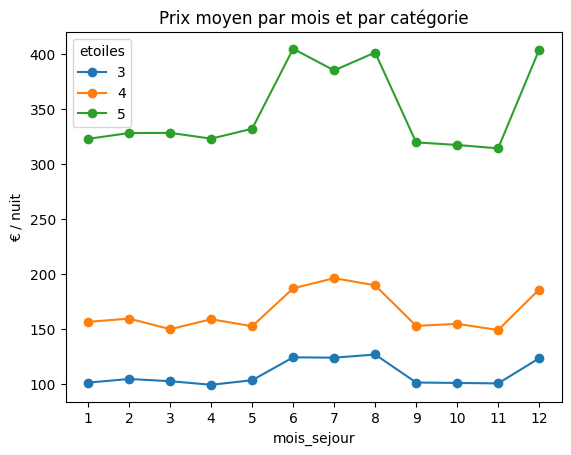

In [16]:
df.groupby(['mois_sejour', 'etoiles']).prix_nuit_eur.mean().unstack().plot(marker='o')
plt.title('Prix moyen par mois et par catégorie'); plt.ylabel('€ / nuit'); plt.xticks(range(1, 13)); plt.show()

**Résultat.** Les trois courbes sont parallèles : la catégorie fixe le niveau, et les mois de juin, juillet, août et décembre sont plus chers pour les trois catégories. Les huit autres mois sont à un niveau comparable.

**Conclusion.** On retient donc deux saisons (haute : 6, 7, 8, 12 ; basse : les autres) plutôt que douze mois, ce qui limite le nombre de paramètres à estimer (chaque mois n'a que 54 à 87 réservations). Ce seuil est déduit des données, il ne nous a pas été fourni par l'entreprise.

### Découper en tranches : le délai de réservation

In [17]:
df['tranche_delai'] = pd.cut(df.delai_reservation_j, [-1, 7, 30, 90, 400])
print(df.groupby('tranche_delai', observed=True).prix_nuit_eur.agg(['count', 'mean']).round(0))

               count   mean
tranche_delai              
(-1, 7]          139  196.0
(7, 30]          277  200.0
(30, 90]         286  189.0
(90, 400]         92  200.0


On découpe le délai de réservation en quatre tranches (0 à 7 jours, 8 à 30, 31 à 90, plus de 90) et on calcule le prix moyen de chaque tranche.

**Résultat.** 196 €, 200 €, 189 € et 200 € : aucune tendance claire.

**Conclusion.** Le délai de réservation n'a pas d'effet visible sur le prix moyen brut. S'il en a un, il est faible ou masqué par l'effet de la catégorie. On le garde dans le modèle pour mesurer son effet à catégorie égale, et on regardera son coefficient.

### Matrice de corrélation

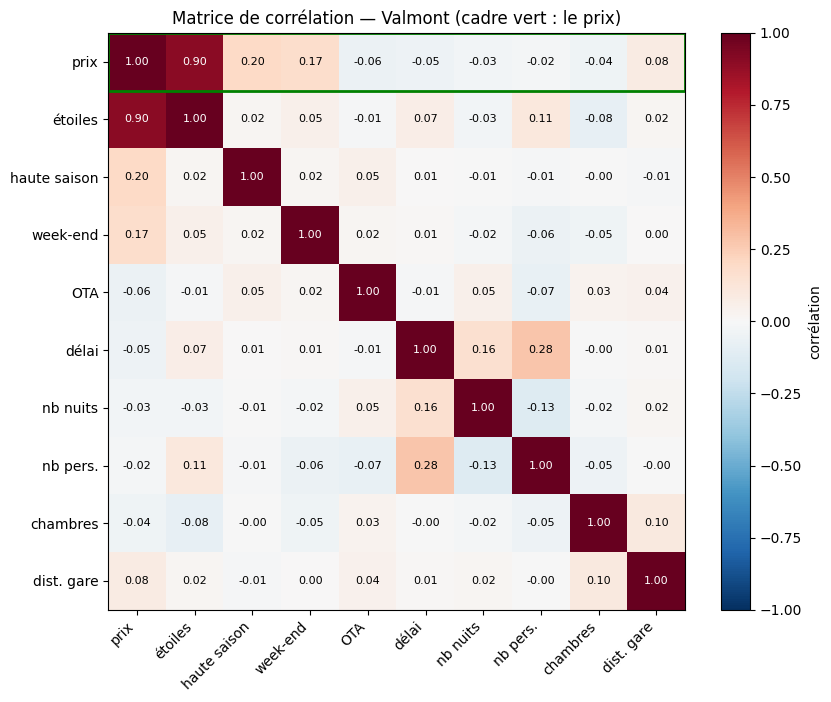

In [18]:
cols_corr = ['prix_nuit_eur', 'etoiles', 'haute', 'we', 'ota', 'delai_reservation_j',
             'nb_nuits', 'nb_personnes', 'chambres', 'distance_gare_km']
noms = ['prix', 'étoiles', 'haute saison', 'week-end', 'OTA', 'délai',
        'nb nuits', 'nb pers.', 'chambres', 'dist. gare']

corr = df[cols_corr].corr()

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)   # rouge = positif, bleu = négatif

ax.set_xticks(range(len(noms)))
ax.set_xticklabels(noms, rotation=45, ha='right')
ax.set_yticks(range(len(noms)))
ax.set_yticklabels(noms)

# écrire la valeur dans chaque case (texte blanc sur les cases foncées)
for i in range(len(noms)):
    for j in range(len(noms)):
        v = corr.values[i, j]
        couleur = 'white' if abs(v) > 0.6 else 'black'
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8, color=couleur)

# cadre vert autour de la ligne du prix
ax.add_patch(plt.Rectangle((-0.5, -0.5), len(noms), 1, fill=False, edgecolor='green', lw=2))

fig.colorbar(im, ax=ax, label='corrélation')
ax.set_title('Matrice de corrélation — Valmont (cadre vert : le prix)')
plt.tight_layout()
plt.show()


 Matrice des corrélations entre le prix et les variables disponibles. La corrélation mesure à quel point deux variables évoluent ensemble en ligne droite, entre −1 et 1. Le cadre vert entoure la ligne du prix.

**Résultat.** Corrélation avec le prix : étoiles +0,90, haute saison +0,20, week-end +0,17, distance à la gare +0,08, plateformes −0,06, délai −0,05, nombre de chambres −0,04, nombre de nuits −0,03, nombre de personnes −0,02. Entre elles, les variables explicatives sont peu corrélées (la plus forte vaut 0,28, entre le délai et le nombre de personnes).

**Conclusion.** Le nombre d'étoiles domine nettement. La corrélation de la saison et du week-end paraît faible, mais elle est diluée par l'écart entre catégories : à l'intérieur d'une même catégorie, elle monte à 0,45 (3étoiles), 0,59 (4étoiles) et 0,68 (5étoiles) pour la saison. On ne les écarte donc pas sur cette seule base. Un nombre de nuits sans lien avec le prix (−0,03) confirme que `prix_nuit_eur` est bien un prix par nuit. Les variables explicatives ne se répètent pas entre elles, on peut toutes les conserver.

### Hypothèses formulées avant de modéliser
- **H1.** La catégorie explique l'essentiel du prix. *Appui : 109 € / 166 € / 349 € en moyenne. Vérification : les coefficients et le R² du modèle.*
- **H2.** La haute saison et le week-end font augmenter le prix de façon notable, de l'ordre de 10 à 25 %. *Appui : les moyennes ci-dessus. Vérification : les coefficients du modèle.*
- **H3.** Une fois la catégorie connue, l'hôtel n'ajoute rien. *Appui : aucune pour l'instant. Vérification : ajouter l'hôtel au modèle et regarder si l'erreur baisse sur des données non vues.*

## 3. Ce que l'on prédit et comment on juge
| Question | Choix |
|---|---|
| Que prédit-on, avec quoi ? | le prix par nuit, à partir de la catégorie, la saison, le week-end, le canal et le délai |
| Quelle forme de modèle ? | une régression linéaire (coefficients interprétables), comparée à un kNN |
| Comment juge-t-on ? | le RMSE en euros et le R², sur des réservations non utilisées pour construire le modèle, comparés à un modèle qui prédit toujours la moyenne |

## 4. Le modèle « moyenne » : le point de comparaison à battre

In [19]:
cols = ['etoiles', 'haute', 'we', 'ota', 'delai_reservation_j']
# les étoiles en 0/1 : 'est un 4 étoiles' et 'est un 5 étoiles' (le3  étoiles est la référence)
X = pd.DataFrame({'est_4etoiles': (df.etoiles == 4).astype(int),
                  'est_5etoiles': (df.etoiles == 5).astype(int),
                  'haute': df.haute, 'we': df.we, 'ota': df.ota,
                  'delai': df.delai_reservation_j})
y = df.prix_nuit_eur

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42)

def rmse(y_vrai, y_prevu):
    return mean_squared_error(y_vrai, y_prevu) ** 0.5

rmse_moyenne = rmse(y_te, np.full(len(y_te), y_tr.mean()))
print('Modèle moyenne : on prédit', round(y_tr.mean()), '€ pour tout le monde -> RMSE =', round(rmse_moyenne, 1), '€')

Modèle moyenne : on prédit 198 € pour tout le monde -> RMSE = 106.3 €


On construit la matrice 'X' des variables explicatives (le3  étoiles est la catégorie de référence, il se reconnaît quand est_4etoiles et est_5etoiles valent 0). On sépare les données en 70 % pour l'apprentissage (555 réservations) et 30 % pour le test (238), tirées au hasard de façon reproductible (random_state=42). On définit le RMSE, l'erreur typique exprimée en euros, puis on calcule celui d'un modèle qui prédit le prix moyen d'apprentissage pour tout le monde.

**Résultat.** Prédire 198 € pour toutes les réservations donne un RMSE de 106,3 €.

**Conclusion.** C'est le point de comparaison : un modèle qui ne fait pas mieux n'a rien appris. Cette erreur de 106 € est énorme puisqu'elle représente plus de la moitié du prix moyen.

## 5. La régression linéaire

In [20]:
modele = LinearRegression()
modele.fit(X_tr, y_tr)

for nom, coef in zip(X.columns, modele.coef_):
    print(f'{nom:15s} {coef:+7.1f} €')
print('constante       ', round(modele.intercept_, 1), '€')

print('\napprentissage : RMSE =', round(rmse(y_tr, modele.predict(X_tr)), 1), ' R2 =', round(r2_score(y_tr, modele.predict(X_tr)), 3))
print('test          : RMSE =', round(rmse(y_te, modele.predict(X_te)), 1), ' R2 =', round(r2_score(y_te, modele.predict(X_te)), 3))

est_4etoiles      +57.1 €
est_5etoiles     +239.2 €
haute             +42.3 €
we                +26.8 €
ota               -12.4 €
delai              -0.3 €
constante        105.2 €

apprentissage : RMSE = 22.7  R2 = 0.953
test          : RMSE = 23.1  R2 = 0.953


On ajuste une régression linéaire sur les données d'apprentissage. Chaque coefficient s'interprète comme la variation du prix, en euros, quand la variable passe de 0 à 1, les autres restant constantes. On calcule ensuite l'erreur (RMSE) et le R² sur l'apprentissage et sur le test.

**Résultat.**
- un 4 étoiles coûte 57 € de plus qu'un 3 étoiles, un 5 étoiles 239 € de plus.
- La haute saison ajoute 42 €, le week-end 27 €.
- Passer par une plateforme retire 12 €, et chaque jour de délai en plus retire 0,3 €.
- RMSE : 22,7 € à l'apprentissage, 23,1 € au test. R² : 0,953 dans les deux cas.

**Conclusion.** Le modèle divise l'erreur par plus de quatre par rapport à la moyenne (106 € contre 23 €) et explique 95 % de la variation des prix. Les résultats sont quasiment identiques à l'apprentissage et au test : le modèle généralise, il ne se contente pas de mémoriser les données. Les hypothèses H1 (la catégorie domine) et H2 (saison et week-end augmentent le prix) sont confirmées. Reste à vérifier que ses erreurs sont régulières, ce que font les résidus.

### Les résidus : le modèle rate-t-il quelque chose ?

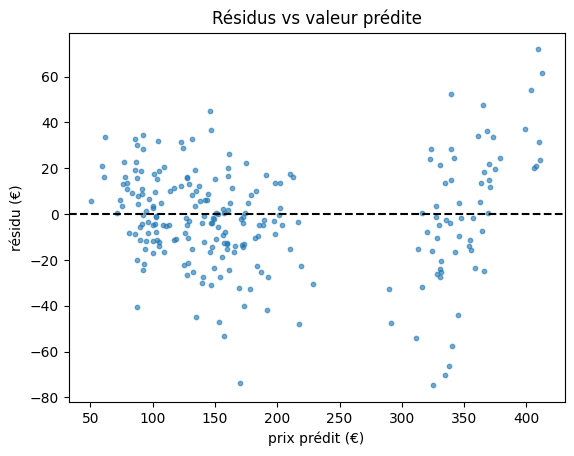

In [21]:
prevu = modele.predict(X_te)
residu = y_te - prevu

plt.scatter(prevu, residu, s=10, alpha=.6)
plt.axhline(0, color='k', ls='--')
plt.xlabel('prix prédit (€)'); plt.ylabel('résidu (€)'); plt.title('Résidus vs valeur prédite'); plt.show()

Un résidu est l'écart entre le prix réel et le prix prédit. On le trace en fonction du prix prédit pour détecter une erreur qui dépendrait du niveau de prix.

**Résultat.** Les points s'étalent de plus en plus autour de zéro quand le prix prédit augmente : l'erreur est faible pour les chambres bon marché et beaucoup plus forte pour les chambres chères (la corrélation entre le prix prédit et la taille de l'erreur est de 0,32).

**Conclusion.** Le modèle est mal adapté sur un point précis : il ajoute des montants fixes (+42 € la haute saison, +27 € le week-end), alors que les effets sont proportionnels. En haute saison, le prix augmente d'environ 22 % pour un  étoiles (+22 €), 23 % pour un 4 étoiles (+35 €) et 23 % pour un 5 étoiles (+75 €) : le pourcentage est stable, pas le montant. Le modèle surestime donc l'effet pour les3  étoiles et le sous-estime pour les5 étoiles. On corrige en prédisant le logarithme du prix, qui transforme des effets multiplicatifs en effets additifs.

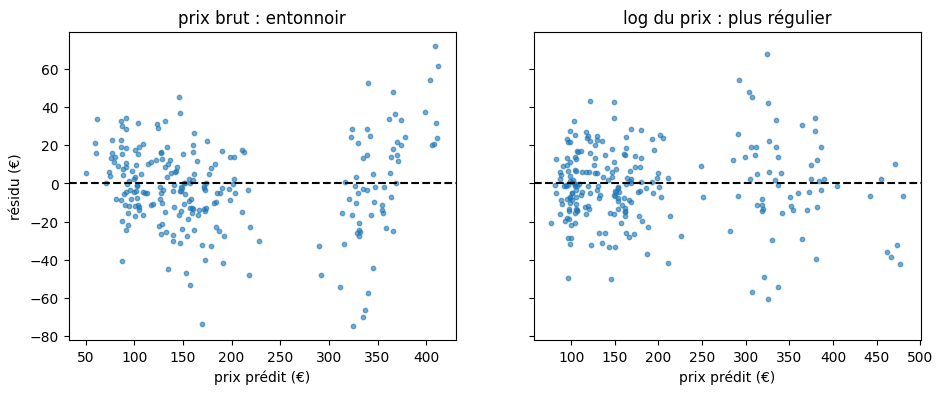

RMSE test : prix brut 23.1 | log du prix 20.1
R2   test : prix brut 0.953 | log du prix 0.964
est_4etoiles     +53.1 %
est_5etoiles    +222.1 %
haute            +23.2 %
we               +13.7 %
ota               -7.2 %
delai             -0.2 %


In [22]:
modele_log = LinearRegression()
modele_log.fit(X_tr, np.log(y_tr))

prevu_log = np.exp(modele_log.predict(X_te))       # exp : retour du log aux euros
residu_log = y_te - prevu_log

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
ax[0].scatter(prevu, residu, s=10, alpha=.6); ax[0].set_title('prix brut : entonnoir')
ax[1].scatter(prevu_log, residu_log, s=10, alpha=.6); ax[1].set_title('log du prix : plus régulier')
for a in ax:
    a.axhline(0, color='k', ls='--'); a.set_xlabel('prix prédit (€)')
ax[0].set_ylabel('résidu (€)'); plt.show()

print('RMSE test : prix brut', round(rmse(y_te, prevu), 1), '| log du prix', round(rmse(y_te, prevu_log), 1))
print('R2   test : prix brut', round(r2_score(y_te, prevu), 3), '| log du prix', round(r2_score(y_te, prevu_log), 3))

# effet de chaque variable en % : exp(coefficient) - 1
for nom, coef in zip(X.columns, modele_log.coef_):
    print(f'{nom:15s} {(np.exp(coef) - 1) * 100:+6.1f} %')

 On refait la régression en prédisant le logarithme du prix (`np.log`), puis on repasse en euros avec `np.exp` pour comparer. Les deux nuages de résidus sont tracés côte à côte. Pour chaque variable, `exp(coefficient) - 1` donne l'effet en pourcentage.

**Résultat.** Le RMSE au test passe de 23,1 € à 20,1 € et le R² de 0,953 à 0,964. Les effets en pourcentage :4 étoiles +53 %,5 étoiles +222 % (par rapport au3  étoiles), haute saison +23,2 %, week-end +13,7 %, plateformes −7,2 %, −0,2 % par jour de délai supplémentaire.

**Conclusion.** Le modèle sur le logarithme est meilleur (erreur réduite d'environ 13 %) et son nuage de résidus est plus régulier. Ses coefficients se lisent directement en pourcentage, ce qui est plus parlant pour une direction commerciale : la haute saison majore le prix d'environ 23 %, le week-end de 14 %, et les plateformes sont environ 7 % moins chères à catégorie, saison et jour égaux (l'écart brut observé plus haut était de 8 %). On retient ce modèle.

### H3 : l'hôtel ajoute-t-il quelque chose à la prédiction ?

In [23]:
kf = KFold(5, shuffle=True, random_state=42)
X_hotel = pd.concat([X, pd.get_dummies(df.hotel_id)], axis=1)

for nom, jeu in [('sans l\'hôtel', X), ('avec l\'hôtel', X_hotel)]:
    s = cross_val_score(LinearRegression(), jeu, np.log(y), cv=kf, scoring='neg_root_mean_squared_error')
    print(nom, ': erreur moyenne sur le log =', round(-s.mean(), 4))

sans l'hôtel : erreur moyenne sur le log = 0.1295
avec l'hôtel : erreur moyenne sur le log = 0.1334


On ajoute au modèle une colonne par hôtel (32 colonnes) et on compare l'erreur avec et sans ces colonnes. La comparaison se fait par validation croisée à 5 blocs : les données sont coupées en 5 parties, chacune sert à tour de rôle de test pendant que le modèle apprend sur les 4 autres.

**Résultat.** Erreur de 0,1295 sans l'hôtel, 0,1334 avec (sur l'échelle du logarithme).

**Conclusion.** Connaître l'hôtel n'améliore pas la prédiction, elle se dégrade légèrement. Chaque hôtel n'a que 14 à 39 réservations, le modèle apprendrait alors du bruit. H3 est confirmée : la catégorie suffit, et la ville, la distance à la gare ou le nombre de chambres n'apportent rien de plus. On ne garde pas l'hôtel dans le modèle.

## 6. kNN pour comparer

On compare la régression à un autre type de modèle, le kNN, qui prédit le prix d'une réservation par la moyenne des prix des k réservations les plus proches. Comme il repose sur des distances, il faut mettre les variables à la même échelle : le délai va jusqu'à 235 jours alors que les autres variables valent 0 ou 1, et sans standardisation il déciderait seul. La standardisation est incluse dans un pipeline afin d'être recalculée à chaque tour de validation, sans utiliser les données du bloc de test.

In [24]:
for k in [1, 3, 5, 10, 15, 20, 30, 50]:
    modele_knn = make_pipeline(StandardScaler(), KNeighborsRegressor(k))
    s = cross_val_score(modele_knn, X, y, cv=kf, scoring='neg_root_mean_squared_error')
    print('k =', k, ' RMSE =', round(-s.mean(), 1), ' écart-type des 5 tours =', round(s.std(), 1))

k = 1  RMSE = 26.4  écart-type des 5 tours = 0.5
k = 3  RMSE = 21.5  écart-type des 5 tours = 0.4
k = 5  RMSE = 20.9  écart-type des 5 tours = 0.7
k = 10  RMSE = 20.4  écart-type des 5 tours = 0.5
k = 15  RMSE = 20.9  écart-type des 5 tours = 0.4
k = 20  RMSE = 21.3  écart-type des 5 tours = 1.1
k = 30  RMSE = 22.8  écart-type des 5 tours = 1.0
k = 50  RMSE = 28.1  écart-type des 5 tours = 1.1


Pour plusieurs valeurs de k, on mesure le RMSE moyen sur 5 blocs de validation croisée, ainsi que l'écart-type entre les 5 blocs (stabilité du résultat).

**Résultat.** RMSE de 26,4 € pour k = 1, 21,5 € pour k = 3, 20,9 € pour k = 5, **20,4 € pour k = 10**, 20,9 € pour k = 15, 21,3 € pour k = 20, 22,8 € pour k = 30 et 28,1 € pour k = 50. L'écart-type entre blocs reste faible (0,4 à 1,1).

**Conclusion.** Le meilleur compromis est k = 10. Avec k = 1, le modèle recopie la réservation la plus proche, donc il suit le bruit ; avec k = 50, il moyenne trop de réservations différentes et lisse les écarts réels entre catégories. La courbe en U confirme qu'un k intermédiaire est le bon choix.

## 7. Comparaison et choix

In [25]:
# même jeu de test pour tous
modele_knn = make_pipeline(StandardScaler(), KNeighborsRegressor(10)).fit(X_tr, y_tr)
prevu_knn = modele_knn.predict(X_te)

comparaison = pd.DataFrame({
    'RMSE test (€)': [rmse_moyenne, rmse(y_te, prevu), rmse(y_te, prevu_log), rmse(y_te, prevu_knn)],
    'R2 test': [0, r2_score(y_te, prevu), r2_score(y_te, prevu_log), r2_score(y_te, prevu_knn)],
}, index=['moyenne pour tous', 'régression (prix brut)', 'régression (log du prix)', 'kNN (k = 10)']).round(3)
comparaison

,RMSE test (€),R2 test
moyenne pour tous,106.271,0.000
régression (prix brut),23.056,0.953
régression (log du prix),20.103,0.964
kNN (k = 10),20.573,0.962


 On réunit les quatre modèles sur le même jeu de test pour une comparaison équitable.

**Conclusion.** Tous les modèles battent très largement la moyenne. La régression sur le logarithme et le kNN sont presque équivalents (20,1 € contre 20,6 €). Nous retenons la régression sur le logarithme : à précision égale, elle est lisible (« le week-end ajoute 14 % »), alors que le kNN ne fournit ni coefficient ni règle explicite. L'énoncé demande un prix défendable, et cet argument est plus important qu'un demi-euro d'écart.

## 8. La grille tarifaire (Q3)

In [26]:
# modèle final : on le réentraîne sur toutes les données
modele_final = LinearRegression().fit(X, np.log(y))

# fourchette : erreurs hors échantillon (validation croisée), par catégorie et saison
df['prevu_cv'] = np.exp(cross_val_predict(LinearRegression(), X, np.log(y), cv=kf))
df['ratio'] = df.prix_nuit_eur / df.prevu_cv         # prix réel / prix prévu
bornes = df.groupby(['etoiles', 'haute']).ratio.quantile([0.10, 0.90]).unstack()

def prix_demande(etoiles, mois, weekend, canal='direct', delai=30):
    x = pd.DataFrame({'est_4etoiles': [int(etoiles == 4)], 'est_5etoiles': [int(etoiles == 5)],
                      'haute': [int(mois in (6, 7, 8, 12))], 'we': [int(weekend)],
                      'ota': [int(canal == 'OTA')], 'delai': [delai]})
    return float(np.exp(modele_final.predict(x))[0])

lignes = []
for etoiles in [3, 4, 5]:
    for haute in [0, 1]:
        for we in [0, 1]:
            p = prix_demande(etoiles, 7 if haute else 3, we)
            lignes.append({'catégorie': f'{etoiles}étoiles', 'saison': 'haute' if haute else 'basse',
                           'période': 'week-end' if we else 'semaine', 'prix': round(p),
                           'min': round(p * bornes.loc[(etoiles, haute), 0.10]),
                           'max': round(p * bornes.loc[(etoiles, haute), 0.90])})
grille = pd.DataFrame(lignes)
grille.to_csv('grille_tarifaire.csv', index=False)
grille

,catégorie,saison,période,prix,min,max
0,3étoiles,basse,semaine,100,79,125
1,3étoiles,basse,week-end,114,91,142
2,3étoiles,haute,semaine,124,101,148
3,3étoiles,haute,week-end,141,115,168
4,4étoiles,basse,semaine,154,131,180
5,4étoiles,basse,week-end,176,150,205
6,4étoiles,haute,semaine,190,168,215
7,4étoiles,haute,week-end,217,191,245
8,5étoiles,basse,semaine,325,292,361
9,5étoiles,basse,week-end,371,332,412


 Le modèle retenu est réentraîné sur l'ensemble des données. On calcule ensuite, pour chaque réservation, une prédiction faite par un modèle qui ne l'a pas vue (cross_val_predict), puis le rapport prix réel / prix prévu. Les 10e et 90e percentiles de ce rapport, par catégorie et saison, donnent une fourchette. La fonction prix_demande calcule le prix d'une demande donnée et la boucle remplit la grille de référence (canal direct, réservation à 30 jours), exportée dans grille_tarifaire.csv.

**Résultat.** La grille va de 100 € (3étoiles, basse saison, semaine) à 458 € (5étoiles, haute saison, week-end), chaque case étant accompagnée d'une fourchette. Par exemple, un 4 étoiles en basse saison en semaine est à 154 € (fourchette 131 à 180 €).

**Conclusion.** La grille répond à la question Q3 : un prix de référence par catégorie, saison et type de jour, avec une marge de ±10 à 20 % selon la case. La fourchette indique à partir de quel écart un prix pratiqué doit être justifié. Limite : le modèle additionne les effets, alors qu'en réalité le surcoût du week-end est plus faible en haute saison pour les3  étoiles (141 € prévus pour3  étoiles haute saison week-end contre environ 127 € en moyenne observée).

In [27]:
print('4étoiles, juillet, week-end, direct, 10 j :', round(prix_demande(4, 7, True, 'direct', 10)), '€')
print('3étoiles, mars, semaine, OTA, 60 j        :', round(prix_demande(3, 3, False, 'OTA', 60)), '€')

4étoiles, juillet, week-end, direct, 10 j : 225 €
3étoiles, mars, semaine, OTA, 60 j        : 88 €


On utilise la fonction pour répondre à deux demandes concrètes.

**Résultat.** un 4 étoiles en juillet, un week-end, en réservation directe 10 jours à l'avance : 225 €. un  étoiles en mars, en semaine, via une plateforme, 60 jours à l'avance : 88 €.

**Conclusion.** Pour toute demande qui arrive, on obtient un prix en quelques millisecondes, qui reste cohérent avec la période (haute ou basse saison, week-end) et l'établissement (via sa catégorie), ainsi qu'avec le canal et le délai.

## 9. Où la grille tient, où elle se trompe (Q4)
On juge sur des réservations que le modèle n'a pas vues : chaque prix est prédit par un modèle entraîné sur les 4 autres paquets de la validation croisée.
Écart = (prix prévu − prix réel) / prix réel. Un « gros écart » dépasse 20 %.

In [28]:
df['ecart'] = (df.prevu_cv - df.prix_nuit_eur) / df.prix_nuit_eur * 100
df['ecart_abs'] = df.ecart.abs()
df['gros_ecart'] = (df.ecart_abs > 20) * 100          # la moyenne de cette colonne donne un %

par_mois = df.groupby('mois_sejour')[['ecart', 'ecart_abs', 'gros_ecart']].mean().round(1)
par_mois.columns = ['biais %', 'erreur moyenne %', '% de gros écarts']
par_mois

,biais %,erreur moyenne %,% de gros écarts
mois_sejour,,,
1,0.9,10.7,13.5
2,-0.9,10.5,10.2
3,-0.3,10.0,13.9
4,3.1,11.8,17.2
5,0.5,11.0,17.3
6,0.6,9.0,3.6
7,-0.7,8.4,1.9
8,1.4,9.1,9.2
9,1.5,9.8,8.8


On compare la prédiction faite hors échantillon au prix réel, réservation par réservation. L'écart est signé (positif si on surestime) ; on en déduit, par mois, le biais (moyenne des écarts avec leur signe, qui dit si la grille se trompe dans un sens), l'erreur moyenne (sans le signe, qui dit de combien elle se trompe) et la part des réservations avec un écart supérieur à 20 %. Ce seuil de 20 % est un choix : il correspond à un tarif manifestement faux.

**Résultat.** Le biais reste compris entre −0,9 % et +3,1 % pour tous les mois. L'erreur moyenne est de 8,4 à 9,1 % en juin, juillet, août et décembre (haute saison), contre 10 à 11,8 % le reste de l'année. La part des écarts supérieurs à 20 % est minimale en juillet (1,9 %) et juin (3,6 %), et maximale en avril et mai (17,2 % et 17,3 %).

**Conclusion.** La grille tient en pleine haute saison : en juillet seules 1,9 % des réservations s'écartent de plus de 20 %, ce qui répond à la contrainte de ne pas appliquer un tarif faux à ce moment-là. Elle ne dérive dans aucun sens (biais proche de zéro). Les mois les moins fiables sont avril et mai, où environ une réservation sur six s'écarte de plus de 20 %.

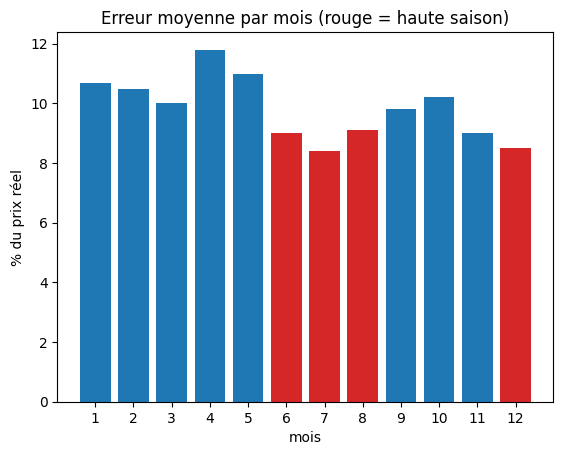

In [29]:
couleurs = ['tab:red' if m in (6, 7, 8, 12) else 'tab:blue' for m in par_mois.index]
plt.bar(par_mois.index, par_mois['erreur moyenne %'], color=couleurs)
plt.title('Erreur moyenne par mois (rouge = haute saison)')
plt.xlabel('mois'); plt.ylabel('% du prix réel'); plt.xticks(range(1, 13)); plt.show()

Diagramme en barres de l'erreur moyenne par mois, les mois de haute saison étant en rouge.

**Résultat.** Les barres rouges (juin, juillet, août, décembre) sont les plus basses, entre 8,4 % et 9,1 %. Avril est le mois le plus haut (11,8 %).

**Conclusion.** L'erreur est plus faible quand la demande est forte. Une grille utilisée en haute saison est donc plus précise qu'en basse saison, ce qui est rassurant pour la période où une erreur coûte le plus cher.

In [30]:
par_segment = df.groupby(['etoiles', 'haute'])[['ecart', 'ecart_abs', 'gros_ecart']].mean().round(1)
par_segment.columns = ['biais %', 'erreur moyenne %', '% de gros écarts']
par_segment.index = par_segment.index.set_names(['étoiles', 'haute saison (1 = oui)'])
par_segment

biais %  erreur moyenne %  % de gros écarts
étoiles haute saison (1 = oui)                                             
3       0                           1.8              13.9              24.6
        1                           1.0              12.7              13.1
4       0                           0.8               9.5               7.5
        1                           0.2               7.6               3.3
5       0                          -0.1               6.6               3.4
        1                           1.1               5.1               0.0

Mêmes indicateurs, calculés par catégorie et par saison.

**Résultat.** L'erreur moyenne va de 5,1 % (5étoiles en haute saison) à 13,9 % (3étoiles en basse saison). La part des écarts supérieurs à 20 % est de 24,6 % pour les3  étoiles en basse saison, 7,5 % pour les4 étoiles en basse saison, 3,4 % pour les5 étoiles en basse saison, et 0 % pour les5 étoiles en haute saison. Les biais restent inférieurs à 2 % dans tous les segments.

**Conclusion.** La grille est d'autant plus fiable que la catégorie est élevée. Le point faible est le3  étoiles en basse saison : un quart des réservations s'écarte de plus de 20 % du prix prévu. En valeur absolue l'écart reste modeste (les prix sont bas, autour de 100 €), mais pour cette case on recommande d'afficher une fourchette plutôt qu'un prix unique.

In [31]:
par_hotel = df.groupby('hotel_id').agg(n=('ecart', 'size'), biais=('ecart', 'mean')).round(1)
par_hotel.sort_values('biais').iloc[[0, 1, 2, -3, -2, -1]]

,n,biais
hotel_id,,
H62,20,-3.8
H44,14,-3.0
H70,26,-2.1
H67,27,5.2
H60,24,7.0
H61,16,7.4


On calcule le biais de chaque hôtel et on affiche les trois plus sous-estimés et les trois plus surestimés.

**Résultat.** Les hôtels H62, H44 et H70 sont les plus sous-estimés ; H67, H60 et H61 les plus surestimés. Chaque hôtel compte entre 14 et 39 réservations.

**Conclusion.** Même pour les hôtels les plus éloignés, l'écart moyen reste inférieur à 8 %. Avec si peu de réservations par hôtel, ces écarts ne sont pas assez solides pour justifier une correction hôtel par hôtel, ce qui est cohérent avec H3. Si ces hôtels continuent à s'écarter avec davantage de données, on pourrait appliquer un ajustement spécifique.

## 10. Synthèse et recommandations

**Hypothèses.**
- H1 confirmée : la catégorie domine (un 5 étoiles vaut environ 3,2 fois un  étoiles ; R² de 0,96).
- H2 confirmée : la haute saison majore le prix d'environ 23 % et le week-end d'environ 14 %.
- H3 confirmée : ajouter l'hôtel n'améliore pas la prédiction.

**Q3, prix défendable.** Appliquer la grille : prix de référence par catégorie, saison et type de jour, ajusté pour le canal (plateformes environ 7 % moins chères) et le délai. Erreur moyenne d'environ 10 % sur des réservations non vues, contre plus de 50 % avec un prix unique.

**Q4, fiabilité.** La grille est la plus fiable en haute saison (juin, juillet, août, décembre) et pour les5 étoiles. Elle est la moins fiable pour les3  étoiles en basse saison et en avril-mai : y afficher une fourchette et faire valider par le revenue manager tout écart important.

**Limites.**
- Le modèle décrit les prix observés, pas la demande : il ne dit pas quel prix maximise le revenu.
- Les effets sont supposés cumulatifs, ce qui surestime légèrement le prix des3  étoiles en haute saison le week-end.
- Le seuil de haute saison (mois 6, 7, 8, 12) est déduit des données.
- Le fichier utilisé contient 794 réservations (l'énoncé en annonce 940).